# Medicaid Spending on GLP-1 Weight-Loss Drugs (Zepbound and Wegovy)

**Question:** how much are state Medicaid programs spending on the GLP-1 weight-loss drugs Zepbound and Wegovy, where is that money going, and does the cost per prescription differ by state?

**Data:** the CMS State Drug Utilization Data for the first two quarters of 2025: 2,637,009 rows covering every drug Medicaid paid for, by state, quarter and package. After removing rows suppressed for privacy and the national total, 838 rows are Zepbound or Wegovy, covering 49 states and territories.

**Approach:** filter and clean the product names, compare the two drugs, total spending and weighted cost per prescription by state, test whether per-prescription cost differs by state (Kruskal-Wallis), and compare GLP-1 spending with all Medicaid drug spending.

**Key results:**
- Medicaid reimbursed $1.68 billion for 1.49 million Zepbound and Wegovy prescriptions in the first half of 2025, 3.20% of all Medicaid drug spending ($52.4 billion).
- Wegovy took 64% of the dollars ($1,175 per prescription vs. $1,043 for Zepbound), but Zepbound is growing fast: its prescriptions rose 41.7% from Q1 to Q2, compared with 6.7% for Wegovy.
- Spending is highly concentrated: five states account for 83.0% of the dollars, led by California ($780 million).
- Per-prescription cost differs significantly by state (p < 0.001), with a median of $1,221 and a few outliers well below it.

**Tools:** Python (pandas, SciPy, matplotlib, seaborn)

**Context:** master's coursework (DSC680, Project 2), cleaned up and corrected for this portfolio.

## 1. Load the data
The full 2025 State Drug Utilization Data file (`sdud-2025-updated-dec2025.csv`, 239 MB, 2,637,009 rows) is too large to publish. When it is in this folder, the notebook rebuilds the two small files it needs from it; otherwise it loads those files directly:
- `zepbound_wegovy_filtered.csv`: every Zepbound and Wegovy row that was not suppressed for privacy, excluding the national total
- `state_reimbursement_all_drugs.csv`: total reimbursement and prescriptions for **all** drugs by state, used for context

The State column holds the 50 states, DC, Puerto Rico, and "XX" (the national total, which is excluded so it is not double counted).

In [1]:
# import required libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')

In [2]:
RAW = 'sdud-2025-updated-dec2025.csv'
if os.path.exists(RAW):
    df = pd.read_csv(RAW)
    print(f'Full file: {len(df):,} rows; State values: {df["State"].nunique()}')
    # Zepbound and Wegovy rows, not suppressed, national total excluded
    df_glp = df[df['Product Name'].str.contains('zepbound|wegovy', case=False, na=False)
                & (df['Suppression Used'].astype(str).str.upper() == 'FALSE')
                & (df['State'] != 'XX')].copy()
    df_glp.to_csv('zepbound_wegovy_filtered.csv', index=False)
    state_all = (df[df['State'] != 'XX'].groupby('State')
                 .agg(total_reimbursed=('Total Amount Reimbursed', 'sum'), prescriptions=('Number of Prescriptions', 'sum'))
                 .reset_index())
    state_all.to_csv('state_reimbursement_all_drugs.csv', index=False)
else:
    df_glp = pd.read_csv('zepbound_wegovy_filtered.csv')
    state_all = pd.read_csv('state_reimbursement_all_drugs.csv')
    print('Full file not found: loaded the filtered GLP-1 file and the state summary.')

print(f'Zepbound and Wegovy rows: {len(df_glp)}   States with data: {df_glp["State"].nunique()}')
df_glp.head()

Full file not found: loaded the filtered GLP-1 file and the state summary.
Zepbound and Wegovy rows: 838   States with data: 49


,Utilization Type,State,NDC,Labeler Code,Product Code,Package Size,Year,Quarter,Suppression Used,Product Name,Units Reimbursed,Number of Prescriptions,Total Amount Reimbursed,Medicaid Amount Reimbursed,Non Medicaid Amount Reimbursed
0,FFSU,AK,2247180,2,2471,80,2025,2,False,ZEPBOUND,52.0,26.0,27472.70,27472.70,0.00
1,FFSU,AK,2248480,2,2484,80,2025,2,False,ZEPBOUND,78.0,39.0,41213.36,40177.10,1036.26
2,FFSU,AK,2249580,2,2495,80,2025,2,False,ZEPBOUND,138.0,69.0,72802.01,71834.65,967.36
3,FFSU,AK,2250680,2,2506,80,2025,2,False,ZEPBOUND,122.0,61.0,64331.00,60274.51,4056.49
4,FFSU,AK,2249580,2,2495,80,2025,1,False,ZEPBOUND,30.0,15.0,15759.32,15759.32,0.00


## 2. Clean and classify

In [3]:
# product names are padded and include doses (for example 'WEGOVY 0.5'), so group them into the two drugs
df_glp['Product Name'] = df_glp['Product Name'].str.strip()
df_glp['Drug'] = np.where(df_glp['Product Name'].str.upper().str.contains('ZEPBOUND'), 'Zepbound', 'Wegovy')
print(df_glp['Drug'].value_counts().to_dict())
print('Quarters:', sorted(df_glp['Quarter'].unique()), '  Utilization types:', df_glp['Utilization Type'].unique().tolist())
print('Missing values:', df_glp.isna().sum().sum())

{'Wegovy': 500, 'Zepbound': 338}
Quarters: [1, 2]   Utilization types: ['FFSU', 'MCOU']
Missing values: 0


## 3. Zepbound vs. Wegovy
Reimbursement per prescription is calculated as total dollars divided by total prescriptions (a weighted average), so large and small rows count in proportion to their size.

In [4]:
by_drug = df_glp.groupby('Drug').agg(prescriptions=('Number of Prescriptions', 'sum'),
                                     total_reimbursed=('Total Amount Reimbursed', 'sum'),
                                     medicaid_reimbursed=('Medicaid Amount Reimbursed', 'sum'))
by_drug['per_prescription'] = by_drug['total_reimbursed'] / by_drug['prescriptions']
by_drug['share_of_dollars'] = by_drug['total_reimbursed'] / by_drug['total_reimbursed'].sum()
print(f"Total reimbursed, both drugs, Q1-Q2 2025: ${by_drug['total_reimbursed'].sum() / 1e6:,.1f} million "
      f"for {by_drug['prescriptions'].sum():,.0f} prescriptions")
by_drug.round(2)

Total reimbursed, both drugs, Q1-Q2 2025: $1,679.1 million for 1,494,724 prescriptions


,prescriptions,total_reimbursed,medicaid_reimbursed,per_prescription,share_of_dollars
Drug,,,,,
Wegovy,912320.0,1.071674e+09,1.058020e+09,1174.67,0.64
Zepbound,582404.0,6.074212e+08,5.970144e+08,1042.96,0.36


Prescriptions by quarter:
Drug       Wegovy  Zepbound
Quarter                    
1        441457.0  240971.0
2        470863.0  341433.0


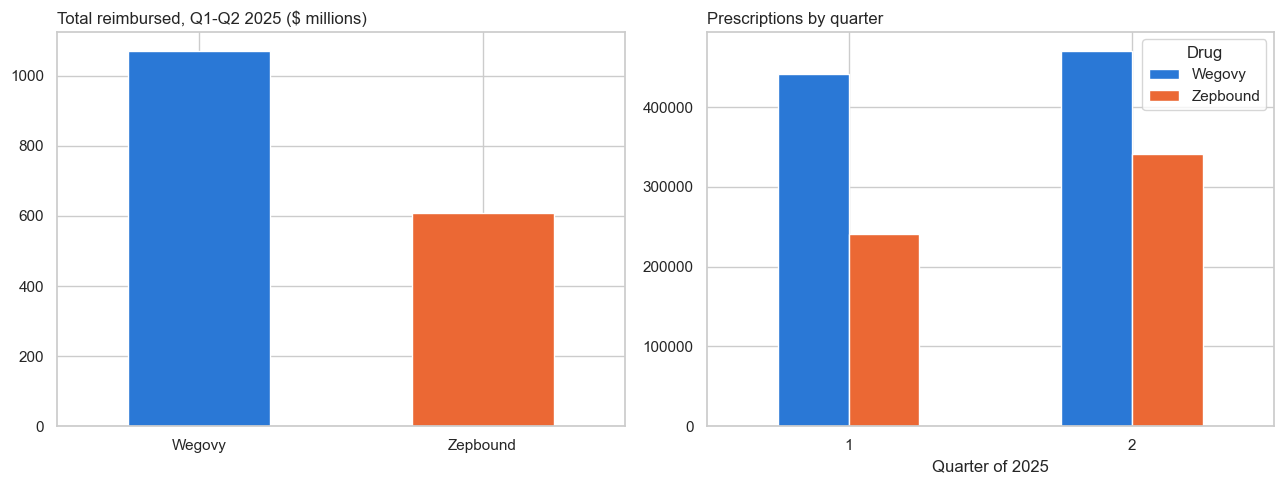

In [5]:
by_quarter = df_glp.pivot_table(index='Quarter', columns='Drug', values='Number of Prescriptions', aggfunc='sum')
print('Prescriptions by quarter:'); print(by_quarter)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
(by_drug['total_reimbursed'] / 1e6).plot(kind='bar', ax=axes[0], color=['#2a78d6', '#eb6834'], rot=0)
axes[0].set_title('Total reimbursed, Q1-Q2 2025 ($ millions)', loc='left'); axes[0].set_xlabel('')
by_quarter.plot(kind='bar', ax=axes[1], color=['#2a78d6', '#eb6834'], rot=0)
axes[1].set_title('Prescriptions by quarter', loc='left'); axes[1].set_xlabel('Quarter of 2025')
plt.tight_layout(); plt.show()

## 4. Where the GLP-1 dollars go, by state

Top 5 states account for 83.0% of Zepbound and Wegovy dollars
       prescriptions  total_reimbursed  per_prescription
State                                                   
CA          636352.0       780197869.0            1226.0
PA          201740.0       246984106.0            1224.0
NC          127059.0       167619571.0            1319.0
MA          101051.0       105205095.0            1041.0
WI           79097.0        92852916.0            1174.0
MI          155608.0        70714374.0             454.0
MN           56121.0        69220708.0            1233.0
MO           22897.0        24014376.0            1049.0
VA           17721.0        21546633.0            1216.0
MS           13543.0        17875154.0            1320.0

Per-prescription cost across states: median $1,221, range $28 to $1,482


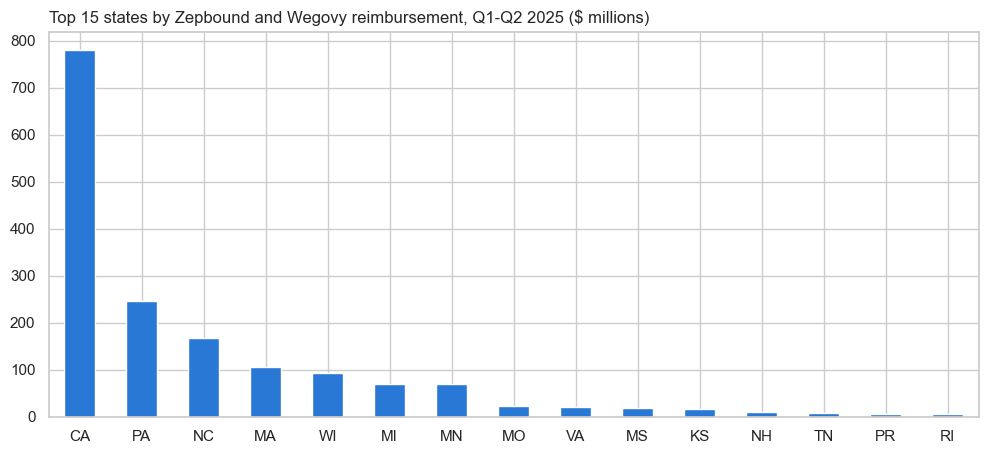

In [6]:
by_state = df_glp.groupby('State').agg(prescriptions=('Number of Prescriptions', 'sum'),
                                       total_reimbursed=('Total Amount Reimbursed', 'sum'))
by_state['per_prescription'] = by_state['total_reimbursed'] / by_state['prescriptions']
by_state = by_state.sort_values('total_reimbursed', ascending=False)
top5_share = by_state['total_reimbursed'].head(5).sum() / by_state['total_reimbursed'].sum()
print(f'Top 5 states account for {top5_share:.1%} of Zepbound and Wegovy dollars')
print(by_state.head(10).round(0))
print(f"\nPer-prescription cost across states: median ${by_state['per_prescription'].median():,.0f}, "
      f"range ${by_state['per_prescription'].min():,.0f} to ${by_state['per_prescription'].max():,.0f}")

fig, ax = plt.subplots(figsize=(12, 5))
(by_state['total_reimbursed'].head(15) / 1e6).plot(kind='bar', ax=ax, color='#2a78d6', rot=0)
ax.set_title('Top 15 states by Zepbound and Wegovy reimbursement, Q1-Q2 2025 ($ millions)', loc='left'); ax.set_xlabel('')
plt.show()

In [7]:
# does the per-prescription cost differ by state more than chance would explain? (Kruskal-Wallis test on the row-level costs)
df_glp_rx = df_glp[df_glp['Number of Prescriptions'] > 0].copy()
df_glp_rx['per_prescription'] = df_glp_rx['Total Amount Reimbursed'] / df_glp_rx['Number of Prescriptions']
groups = [g['per_prescription'].values for _, g in df_glp_rx.groupby('State') if len(g) >= 3]
stat, p_value = stats.kruskal(*groups)
print(f'Kruskal-Wallis across {len(groups)} states (with at least 3 rows): H = {stat:.1f}, p = {p_value:.2g}')
for drug in ['Zepbound', 'Wegovy']:
    sub = df_glp_rx[df_glp_rx['Drug'] == drug]
    g = [x['per_prescription'].values for _, x in sub.groupby('State') if len(x) >= 3]
    s, p = stats.kruskal(*g)
    print(f'  {drug} only: {len(g)} states, H = {s:.1f}, p = {p:.2g}')

Kruskal-Wallis across 47 states (with at least 3 rows): H = 380.8, p = 2.9e-54
  Zepbound only: 30 states, H = 233.4, p = 8.4e-34
  Wegovy only: 44 states, H = 318.6, p = 9.6e-44


## 5. Context: GLP-1 spending compared with all Medicaid drug spending

In [8]:
context = state_all.set_index('State').join(by_state[['total_reimbursed']].rename(columns={'total_reimbursed': 'glp1_reimbursed'}))
context['glp1_share'] = context['glp1_reimbursed'] / context['total_reimbursed']
print(f"All Medicaid drug reimbursement, Q1-Q2 2025 (states, DC and PR): ${context['total_reimbursed'].sum() / 1e9:,.1f} billion")
print(f"Zepbound and Wegovy share of that total: {context['glp1_reimbursed'].sum() / context['total_reimbursed'].sum():.2%}")
print('\nTop 5 states by all-drug reimbursement ($ billions):')
print((context['total_reimbursed'].sort_values(ascending=False).head(5) / 1e9).round(2).to_string())
print('\nStates where Zepbound and Wegovy are the largest share of drug spending:')
print((context['glp1_share'].dropna().sort_values(ascending=False).head(5) * 100).round(2).to_string())

All Medicaid drug reimbursement, Q1-Q2 2025 (states, DC and PR): $52.4 billion
Zepbound and Wegovy share of that total: 3.20%

Top 5 states by all-drug reimbursement ($ billions):
State
CA    8.14
NY    6.08
PA    2.64
OH    2.29
NC    2.27

States where Zepbound and Wegovy are the largest share of drug spending:
State
CA    9.58
PA    9.34
WI    8.63
MN    8.59
MA    8.30


## Findings
- **The scale:** Medicaid paid $1.68 billion for 1,494,724 Zepbound and Wegovy prescriptions in Q1 and Q2 2025. That is 3.20% of the $52.4 billion Medicaid spent on all drugs in those states and territories.
- **Wegovy leads, Zepbound is catching up.** Wegovy accounted for 64% of the dollars and 912,320 prescriptions at $1,175 each; Zepbound for 36% and 582,404 prescriptions at $1,043 each. Zepbound prescriptions grew 41.7% from Q1 to Q2 (240,971 to 341,433), while Wegovy grew 6.7%.
- **A few states drive most of the spending.** California alone reimbursed $780 million (636,352 prescriptions), followed by Pennsylvania ($247 million), North Carolina ($168 million), Massachusetts ($105 million) and Wisconsin ($93 million). Together these five are 83.0% of the total. In California, Pennsylvania, Wisconsin, Minnesota and Massachusetts these two drugs are 8.3% to 9.6% of all Medicaid drug spending, far above the national 3.20%.
- **Coverage is uneven.** New York, North Dakota and South Dakota have no unsuppressed Zepbound or Wegovy rows at all, even though New York is the second-largest Medicaid drug spender overall ($6.08 billion).
- **Cost per prescription varies by state.** Most states pay $1,000 to $1,350 per prescription (median $1,221), and the Kruskal-Wallis test confirms the differences are larger than chance (H = 380.8, p < 0.001), for each drug separately as well. A few states are far below the rest, notably Delaware ($28) and Michigan ($454), which more likely reflects how those states report reimbursements than a real price difference and would be worth confirming before drawing conclusions.
- **Limitations:** about half of all rows in the full file are suppressed for privacy (small counts), so smaller states are under-represented; the data covers only two quarters; and reimbursement amounts are before manufacturer rebates, so they overstate the net cost to states.

**Correction note:** the original notebook switched partway through from Zepbound and Wegovy to all Medicaid drugs without labeling it, so its state totals and its Kruskal-Wallis test described all drug spending rather than these two drugs. It also averaged row-level costs without weighting by prescriptions. This version labels the all-drug figures as context, runs the test on the GLP-1 data, and uses weighted per-prescription costs. The original notebook is in `earlier_versions/`.